# Chapitre 5 - Exercices 5.6 à 5.10

Splines périodiques, dérivation des splines de lissage, schéma de calcul en base de
B-splines, forme de Reinsch, biais et variance d'une spline de lissage.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline, make_interp_spline
from scipy.linalg import null_space, solveh_banded
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl.ch05_splines import (truncated_power_basis, bspline_basis, bspline_penalty_matrix,
                              natural_spline_basis, SmoothingSpline)
set_style()

## Exercice 5.6 : Splines périodiques

**Énoncé.** On veut ajuster une fonction périodique de période $T$ connue. Comment
modifier la base des puissances tronquées pour obtenir ce résultat ?

**Idée.** Une fonction $T$-périodique est déterminée par sa restriction à $[0, T)$. On
remplace donc $x$ par $\tilde x = x \bmod T \in [0, T)$ et l'on écrit, avec des nœuds
$0 < \xi_1 < \dots < \xi_K < T$,

$$
f(x) = \sum_{j=0}^{3}\beta_j\tilde x^j + \sum_{k=1}^{K}\theta_k(\tilde x - \xi_k)_+^3 .
$$

Cette fonction est périodique par construction, et $C^2$ sur $(0, T)$. Mais au point de
recollement $\tilde x = 0 \equiv T$, rien n'assure la régularité : il faut imposer
$f^{(r)}(T^-) = f^{(r)}(0^+)$ pour $r = 0, 1, 2$.

**Les trois contraintes.** En dérivant terme à terme ($\frac{d^r}{dx^r}x^j =
\frac{j!}{(j-r)!}x^{j-r}$ et de même pour les puissances tronquées) :

$$
\begin{aligned}
r = 0 :&\quad \beta_1T + \beta_2T^2 + \beta_3T^3 + \textstyle\sum_k\theta_k(T - \xi_k)^3 = 0,\\
r = 1 :&\quad 2\beta_2T + 3\beta_3T^2 + 3\textstyle\sum_k\theta_k(T - \xi_k)^2 = 0,\\
r = 2 :&\quad 6\beta_3T + 6\textstyle\sum_k\theta_k(T - \xi_k) = 0 .
\end{aligned}
$$

(À gauche de $\xi_1$, en $0^+$, seul le polynôme compte : $f(0^+) = \beta_0$,
$f'(0^+) = \beta_1$, $f''(0^+) = 2\beta_2$, ce qui a été soustrait.) Ce sont 3 contraintes
linéaires sur $K + 4$ coefficients : l'espace des splines cubiques périodiques est de
dimension $K + 1$ - autant que de nœuds sur le cercle ($0$ joue le rôle d'un nœud
supplémentaire, où seule la dérivée troisième peut sauter).

**Base explicite.** Si $\mathbf C$ est la matrice $3 \times (K + 4)$ des contraintes, une
base de son noyau $\mathbf V$ ($(K+4) \times (K+1)$) fournit la base périodique
$\mathbf H_{\text{pér}}(x) = \mathbf H(\tilde x)\mathbf V$. Implémentation :

In [2]:
def periodic_spline_basis(x, knots, T):
    """Base de splines cubiques T-périodiques (puissances tronquées + 3 contraintes)."""
    knots = np.asarray(knots, float)
    C = np.zeros((3, 4 + len(knots)))
    fact = [1, 1, 2, 6]
    for r in range(3):
        for j in range(r, 4):                    # x^j : dérivée r-ième en T moins en 0
            C[r, j] = fact[j] / fact[j - r] * T ** (j - r) - (fact[r] if j == r else 0)
        C[r, 4:] = fact[3] / fact[3 - r] * (T - knots) ** (3 - r)
    V = null_space(C)
    return truncated_power_basis(np.mod(x, T), knots) @ V

T = 1.0
kn = np.linspace(0, 1, 10)[1:-1]
print("dimension de la base périodique :", periodic_spline_basis(np.array([0.1]), kn, T).shape[1])

dimension de la base périodique : 9


**Illustration.** On observe une fonction de période 1 sur une seule période, et l'on
prolonge l'ajustement sur trois périodes. La spline cubique usuelle, recopiée
périodiquement, présente un saut au recollement ; la spline périodique est lisse.

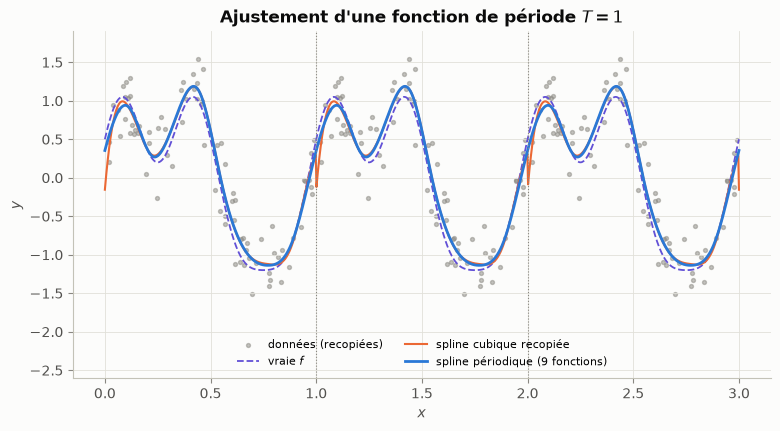

In [3]:
rng = np.random.RandomState(0)
f_per = lambda t: np.sin(2 * np.pi * t) + 0.5 * np.cos(4 * np.pi * t) + 0.3 * np.sin(6 * np.pi * t)
xo = np.sort(rng.uniform(0, 1, 80))
yo = f_per(xo) + 0.3 * rng.randn(80)
grille = np.linspace(0, 3, 900)

Hp = periodic_spline_basis(xo, kn, T)
cp = np.linalg.lstsq(Hp, yo, rcond=None)[0]
Hu = truncated_power_basis(xo, kn)
cu = np.linalg.lstsq(Hu, yo, rcond=None)[0]

plt.figure(figsize=(9, 4.5))
plt.scatter(np.concatenate([xo, xo + 1, xo + 2]), np.tile(yo, 3), s=8, color=GRAY, alpha=0.5,
            label="données (recopiées)")
plt.plot(grille, f_per(grille), color=COLORS[6], ls="--", lw=1.3, label="vraie $f$")
plt.plot(grille, truncated_power_basis(np.mod(grille, T), kn) @ cu, color=ORANGE, lw=1.5,
         label="spline cubique recopiée")
plt.plot(grille, periodic_spline_basis(grille, kn, T) @ cp, color=BLUE, lw=2,
         label="spline périodique (%d fonctions)" % Hp.shape[1])
for k in [1, 2]:
    plt.axvline(k, color=GRAY, lw=0.8, ls=":")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.title("Ajustement d'une fonction de période $T = 1$")
plt.ylim(-2.6, 1.9)
plt.legend(fontsize=8, ncol=2, loc="lower center")
plt.show()

Vérifions la régularité au recollement en comparant les dérivées exactes de la
représentation (puissances tronquées) en $T^-$ et en $0^+$.

In [4]:
def derivee_tronquee(t, knots, r):
    """Dérivée r-ième exacte des colonnes de truncated_power_basis(t, knots)."""
    fact = [1, 1, 2, 6]
    cols = [fact[j] / fact[j - r] * t ** (j - r) if j >= r else np.zeros_like(t) for j in range(4)]
    cols += [fact[3] / fact[3 - r] * np.where(t > k, (t - k) ** (3 - r), 0.0) for k in knots]
    return np.column_stack(cols)

V = null_space(np.vstack([derivee_tronquee(np.array([T]), kn, r) - derivee_tronquee(np.array([0.0]), kn, r)
                          for r in range(3)]))
coef_tp = V @ np.linalg.lstsq(truncated_power_basis(xo, kn) @ V, yo, rcond=None)[0]
for r, nom in enumerate(["f", "f'", "f''", "f'''"]):
    gauche = (derivee_tronquee(np.array([T]), kn, r) @ coef_tp)[0]
    droite = (derivee_tronquee(np.array([0.0]), kn, r) @ coef_tp)[0]
    print("%-5s : en T^- = %+9.4f | en 0^+ = %+9.4f" % (nom, gauche, droite))

f     : en T^- =   +0.3541 | en 0^+ =   +0.3541
f'    : en T^- =  +10.4984 | en 0^+ =  +10.4984
f''   : en T^- =  -56.5679 | en 0^+ =  -56.5679
f'''  : en T^- = -1518.6217 | en 0^+ = -1090.3862


$f$, $f'$ et $f''$ se recollent ; seule $f'''$ saute en $0 \equiv T$, qui se comporte
bien comme un nœud supplémentaire.

> **Remarque.** Une alternative classique pour une fonction périodique est la base de
> Fourier $\{1, \cos(2\pi kx/T), \sin(2\pi kx/T)\}$, périodique et infiniment dérivable,
> mais non locale.

> **À retenir.** Composer avec $x \bmod T$ assure la périodicité ; la régularité au
> point de recollement s'obtient par 3 contraintes linéaires
> $f^{(r)}(T^-) = f^{(r)}(0^+)$, $r = 0, 1, 2$, d'où une base de dimension $K + 1$.

## Exercice 5.7 : Dérivation des splines de lissage

**Énoncé.** Soit $N \ge 2$, $a < x_1 < \dots < x_N < b$, et $g$ la spline cubique
naturelle interpolant les points $(x_i, z_i)$. Soit $\tilde g$ une autre fonction
(deux fois dérivable) sur $[a, b]$ interpolant les mêmes points, et $h = \tilde g - g$.

(a) Montrer (éq. (5.72)) $\int_a^b g''h'' = -\sum_{j=1}^{N-1}g'''(x_j^+)\{h(x_{j+1}) -
    h(x_j)\} = 0$.
(b) En déduire $\int_a^b\tilde g''^2 \ge \int_a^b g''^2$, avec égalité seulement si
    $h \equiv 0$.
(c) En déduire que le minimiseur du critère pénalisé (5.9) est une spline cubique (naturelle)
    à nœuds aux $x_i$.

**Rappels sur $g$.** $g$ est linéaire sur $[a, x_1]$ et sur $[x_N, b]$ (spline naturelle),
cubique sur chaque $[x_j, x_{j+1}]$, de classe $C^2$. Donc $g'' = 0$ sur $[a, x_1]$ et
$[x_N, b]$ (en particulier $g''(a) = g''(b) = 0$), et $g'''$ est **constante** sur chaque
$(x_j, x_{j+1})$, égale à $g'''(x_j^+)$, et nulle hors de $[x_1, x_N]$.

**(a)** Intégration par parties ($u = g''$, $dv = h''dx$) :

$$
\int_a^b g''h'' = \big[g''h'\big]_a^b - \int_a^b g'''h' = 0 - \int_a^b g'''h',
$$

car $g''(a) = g''(b) = 0$. ($g'''$ n'est définie que par morceaux, on intègre donc sur
chaque intervalle où $g''$ est affine, et les termes de bord intermédiaires se
compensent par continuité de $g''$ et $h'$.) Puis, $g'''$ étant constante par morceaux et
nulle hors de $[x_1, x_N]$ :

$$
\int_a^b g'''h' = \sum_{j=1}^{N-1}g'''(x_j^+)\int_{x_j}^{x_{j+1}}h'(x)\,dx
  = \sum_{j=1}^{N-1}g'''(x_j^+)\{h(x_{j+1}) - h(x_j)\}.
$$

Enfin $h(x_j) = \tilde g(x_j) - g(x_j) = z_j - z_j = 0$ pour tout $j$ : la somme est nulle.

**(b)** On développe le carré :

$$
\int_a^b\tilde g''^2 = \int_a^b(g'' + h'')^2 = \int_a^b g''^2 + 2\underbrace{\int_a^b
g''h''}_{=0\ \text{par (a)}} + \int_a^b h''^2 \;\ge\; \int_a^b g''^2 .
$$

Égalité ssi $\int_a^b h''^2 = 0$, i.e. (pour $h''$ continue) $h'' \equiv 0$ : $h$ est
affine. Comme $h(x_1) = h(x_2) = 0$ avec $x_1 \ne x_2$ (c'est là que sert $N \ge 2$), $h$
est identiquement nulle.

**(c)** Soit $f$ une fonction quelconque (deux fois dérivable) et $g$ la spline naturelle
interpolant les points $(x_i, f(x_i))$. Alors $g(x_i) = f(x_i)$ : le terme
$\sum_i(y_i - f(x_i))^2$ est **le même** pour $f$ et $g$, et par (b)
$\int f''^2 \ge \int g''^2$, avec égalité ssi $f = g$. Donc
$\mathrm{RSS}(g, \lambda) \le \mathrm{RSS}(f, \lambda)$, strictement si $f \ne g$ (et
$\lambda > 0$). Un minimiseur est donc nécessairement une spline cubique naturelle à nœuds
aux $x_i$ ; on est ramené au problème de dimension finie (5.11).

**Vérification numérique.** On compare la spline naturelle interpolante à d'autres
interpolants : la spline « not-a-knot », la spline à pentes imposées nulles aux bords, et
$g + h$ avec $h$ une perturbation lisse nulle aux $x_i$.

In [5]:
rng = np.random.RandomState(0)
xk = np.linspace(0.1, 0.9, 8) + 0.02 * rng.randn(8)
zk = rng.randn(8)
tt = np.linspace(xk[0], xk[-1], 200001)    # g'' = 0 hors de [x_1, x_N] : on intègre sur [x_1, x_N]

def courbure(d2):
    return np.trapezoid(d2 ** 2, tt)

g_nat = CubicSpline(xk, zk, bc_type="natural")
h = 2 * np.sin(np.pi * (tt - xk[0]) / (xk[-1] - xk[0])) * np.prod([tt - x for x in xk], axis=0) * 1e4
d2h = np.gradient(np.gradient(h, tt), tt)
candidats = {
    "spline naturelle (g)": g_nat(tt, 2),
    "spline not-a-knot": CubicSpline(xk, zk, bc_type="not-a-knot")(tt, 2),
    "spline à pentes nulles": CubicSpline(xk, zk, bc_type="clamped")(tt, 2),
    "g + h (perturbation)": g_nat(tt, 2) + d2h,
}
for nom, d2 in candidats.items():
    print("%-24s : intégrale de f''^2 = %8.2f" % (nom, courbure(d2)))
print("max |h(x_i)| =", np.abs(np.interp(xk, tt, h)).max())

spline naturelle (g)     : intégrale de f''^2 = 11953.07
spline not-a-knot        : intégrale de f''^2 = 16410.12
spline à pentes nulles   : intégrale de f''^2 = 15119.25
g + h (perturbation)     : intégrale de f''^2 = 12467.78
max |h(x_i)| = 1.1622156693914305e-11


In [6]:
print("intégrale de g'' h'' = %.2e   (à comparer à int h''^2 = %.2f)"
      % (np.trapezoid(g_nat(tt, 2) * d2h, tt), courbure(d2h)))

intégrale de g'' h'' = -5.65e-07   (à comparer à int h''^2 = 514.71)


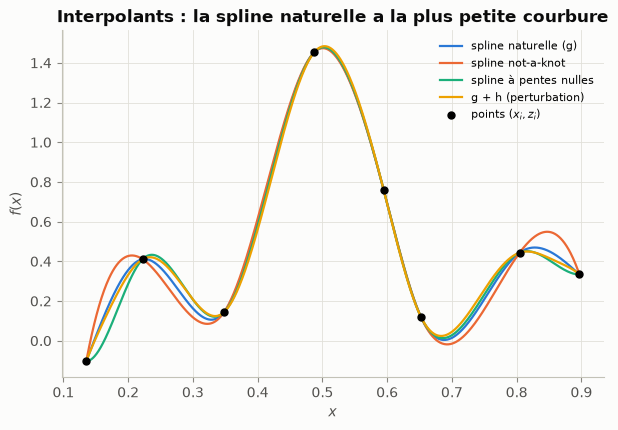

In [7]:
valeurs = {
    "spline naturelle (g)": g_nat(tt),
    "spline not-a-knot": CubicSpline(xk, zk, bc_type="not-a-knot")(tt),
    "spline à pentes nulles": CubicSpline(xk, zk, bc_type="clamped")(tt),
    "g + h (perturbation)": g_nat(tt) + h,
}
plt.figure(figsize=(7, 4.5))
for c, (nom, v) in zip(COLORS, valeurs.items()):
    plt.plot(tt[::200], v[::200], color=c, lw=1.6, label=nom)
plt.scatter(xk, zk, color="k", zorder=5, label="points $(x_i, z_i)$")
plt.xlabel("$x$")
plt.ylabel("$f(x)$")
plt.title("Interpolants : la spline naturelle a la plus petite courbure")
plt.legend(fontsize=8)
plt.show()

> **À retenir.** Parmi toutes les fonctions qui interpolent des points, la spline cubique
> naturelle minimise $\int f''^2$ ; c'est pourquoi la spline de lissage, problème posé en
> dimension infinie, a une solution dans un espace de dimension $N$.

## Exercice 5.8 : Un schéma de calcul plus simple en B-splines

**Énoncé.** L'annexe calcule la spline de lissage dans une base de $N + 4$ B-splines.
Décrire un schéma un peu plus simple utilisant une base de $N + 2$ B-splines construite
sur les $N - 2$ nœuds intérieurs.

**Schéma.** Supposons les $x_i$ distincts et triés. Prenons comme nœuds de bord
$\xi_0 = x_1$, $\xi_{K+1} = x_N$ et comme nœuds intérieurs $x_2, \dots, x_{N-1}$
($K = N - 2$). L'espace des splines cubiques sur $[x_1, x_N]$ correspondant est de
dimension $K + 4 = N + 2$ (base de B-splines $B_1, \dots, B_{N+2}$).

- Cet espace **contient** la restriction à $[x_1, x_N]$ de toute spline naturelle à
  nœuds $x_1, \dots, x_N$ (elle est cubique par morceaux, $C^2$, avec cassures aux $x_i$).
- Le critère restreint $\sum_i(y_i - f(x_i))^2 + \lambda\int_{x_1}^{x_N}f''^2$ est
  minimisé, par l'exercice 5.7 appliqué avec $[a, b] = [x_1, x_N]$, par la spline
  naturelle (qui vérifie $f''(x_1) = f''(x_N) = 0$). Ce minimiseur appartient à l'espace
  des B-splines, donc il est aussi le minimiseur dans cet espace.

On calcule donc $\hat\gamma = (\mathbf B^T\mathbf B + \lambda\Omega_B)^{-1}\mathbf
B^T\mathbf y$ avec $\mathbf B$ de taille $N \times (N + 2)$ et
$\{\Omega_B\}_{jk} = \int_{x_1}^{x_N}B_j''B_k''$, puis on **prolonge linéairement**
$\hat f$ hors de $[x_1, x_N]$. Les conditions $\hat f''(x_1) = \hat f''(x_N) = 0$ ne sont
pas imposées : elles sortent automatiquement de l'optimisation. C'est exactement ce que
fait `SmoothingSpline`.